In [792]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

In [793]:
df = pd.read_csv('Cleaned_Laptop_data.csv')
df = df.dropna()

In [794]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 842 entries, 0 to 844
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   brand            842 non-null    object 
 1   model            842 non-null    object 
 2   processor_brand  842 non-null    object 
 3   processor_Name   842 non-null    object 
 4   processor_gnrtn  842 non-null    object 
 5   ram_gb           842 non-null    float64
 6   Apps             842 non-null    object 
 7   ssd              842 non-null    int64  
 8   hdd              842 non-null    int64  
 9   os               842 non-null    object 
 10  os_bit           842 non-null    int64  
 11  graphic_card_gb  842 non-null    int64  
 12  weight           842 non-null    object 
 13  display_size     842 non-null    object 
 14  warranty         842 non-null    int64  
 15  Touchscreen      842 non-null    object 
 16  msoffice         842 non-null    object 
 17  Price            842 

In [795]:
df['brand'].value_counts()

,count
brand,
ASUS,245
DELL,146
Lenovo,138
HP,132
acer,52
MSI,51
APPLE,27
Avita,10
LG,5


In [796]:
df['brand'] = df['brand'].str.lower()

In [797]:
df['brand'].value_counts()

,count
brand,
asus,245
dell,146
lenovo,141
hp,132
acer,52
msi,51
apple,27
avita,10
lg,5


In [798]:
df['model'].sort_values().unique()

array(['14a', '14s', '15', '15-ec1105AX', '15q', '15s', '2020', '2021',
       '250-G6', '3000', '3511', '430', 'A6-9225', 'AMD', 'APU', 'ASUS',
       'Alpha', 'Aspire', 'Asus', 'Athlon', 'B50-70', 'Book',
       'Book(Slim)', 'Bravo', 'Celeron', 'Chromebook', 'Commercial',
       'CompBook', 'ConceptD', 'Core', 'Cosmos', 'Creator', 'DA', 'DELL',
       'Delta', 'Dual', 'E', 'EeeBook', 'Envy', 'ExpertBook', 'Extensa',
       'F17', 'G15', 'G3', 'G5', 'G7', 'GAMING', 'GE76', 'GF63', 'GF65',
       'GP65', 'GP76', 'GS', 'GS66', 'Galaxy', 'Gram', 'HP', 'IDEAPAD',
       'INBook', 'INSPIRON', 'IdeaPad', 'Ideapad', 'Inpiron', 'Inspiron',
       'Intel', 'Katana', 'Legion', 'Lenovo', 'Liber', 'MacBook',
       'Modern', 'Nitro', 'Notebook', 'OMEN', 'Omen', 'PURA', 'Pavilion',
       'Pentium', 'Predator', 'Prestige', 'Pro', 'Pulse', 'PureBook',
       'ROG', 'Rog', 'Ryzen', 'SE', 'Spectre', 'Spin', 'Stealth',
       'Summit', 'Surface', 'Swift', 'Sword', 'TUF', 'ThinkBook',
       'ThinkPad

In [799]:
df['model'] = df['model'].str.lower()

In [800]:
df['model'].sort_values().unique()

array(['14a', '14s', '15', '15-ec1105ax', '15q', '15s', '2020', '2021',
       '250-g6', '3000', '3511', '430', 'a6-9225', 'alpha', 'amd', 'apu',
       'aspire', 'asus', 'athlon', 'b50-70', 'book', 'book(slim)',
       'bravo', 'celeron', 'chromebook', 'commercial', 'compbook',
       'conceptd', 'core', 'cosmos', 'creator', 'da', 'dell', 'delta',
       'dual', 'e', 'eeebook', 'envy', 'expertbook', 'extensa', 'f17',
       'g15', 'g3', 'g5', 'g7', 'galaxy', 'gaming', 'ge76', 'gf63',
       'gf65', 'gp65', 'gp76', 'gram', 'gs', 'gs66', 'hp', 'ideapad',
       'inbook', 'inpiron', 'inspiron', 'intel', 'katana', 'legion',
       'lenovo', 'liber', 'macbook', 'modern', 'nitro', 'notebook',
       'omen', 'pavilion', 'pentium', 'predator', 'prestige', 'pro',
       'pulse', 'pura', 'purebook', 'rog', 'ryzen', 'se', 'spectre',
       'spin', 'stealth', 'summit', 'surface', 'swift', 'sword', 't.book',
       'thinkbook', 'thinkpad', 'thinpad', 'travelmate', 'tuf', 'v15',
       'vivo', 'viv

In [801]:
df['model'] = df['model'].replace('Inpiron', 'Inspiron')

In [802]:
df['model'].sort_values().unique()

array(['14a', '14s', '15', '15-ec1105ax', '15q', '15s', '2020', '2021',
       '250-g6', '3000', '3511', '430', 'a6-9225', 'alpha', 'amd', 'apu',
       'aspire', 'asus', 'athlon', 'b50-70', 'book', 'book(slim)',
       'bravo', 'celeron', 'chromebook', 'commercial', 'compbook',
       'conceptd', 'core', 'cosmos', 'creator', 'da', 'dell', 'delta',
       'dual', 'e', 'eeebook', 'envy', 'expertbook', 'extensa', 'f17',
       'g15', 'g3', 'g5', 'g7', 'galaxy', 'gaming', 'ge76', 'gf63',
       'gf65', 'gp65', 'gp76', 'gram', 'gs', 'gs66', 'hp', 'ideapad',
       'inbook', 'inpiron', 'inspiron', 'intel', 'katana', 'legion',
       'lenovo', 'liber', 'macbook', 'modern', 'nitro', 'notebook',
       'omen', 'pavilion', 'pentium', 'predator', 'prestige', 'pro',
       'pulse', 'pura', 'purebook', 'rog', 'ryzen', 'se', 'spectre',
       'spin', 'stealth', 'summit', 'surface', 'swift', 'sword', 't.book',
       'thinkbook', 'thinkpad', 'thinpad', 'travelmate', 'tuf', 'v15',
       'vivo', 'viv

In [803]:
df['processor_brand'].value_counts()

,count
processor_brand,
Intel,597
AMD,204
Apple,23
NVIDIA,7
MediaTek,3
Pre-installed,3
First,2
Qualcomm,1
512,1


In [804]:
df['processor_brand'] = df['processor_brand'].replace('Pre-installed', 'Intel')
df['processor_brand'] = df['processor_brand'].replace('First', 'Intel')
df['processor_brand'] = df['processor_brand'].replace('512', 'Intel')
df['processor_brand'] = df['processor_brand'].replace('M.2', 'Intel')


In [805]:
df['processor_brand'].value_counts()

,count
processor_brand,
Intel,604
AMD,204
Apple,23
NVIDIA,7
MediaTek,3
Qualcomm,1


In [806]:
df['processor_Name'].value_counts()

,count
processor_Name,
Core i5,274
Core i3,157
Core i7,103
Ryzen 5,82
Ryzen 7,57
Ryzen 9,26
Ryzen 3,24
Celeron Dual,19
M1 Processor,17


In [807]:
df['processor_Name'] = df['processor_Name'].replace('i5', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('i7', 'Core i7')
df['processor_Name'] = df['processor_Name'].replace('GEFORCE RTX', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('GeForce GTX', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('Genuine Windows', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('MediaTek Kompanio', 'Kompanio352')
df['processor_Name'] = df['processor_Name'].replace('Ever Screenpad', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('GB SSD', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('Slot for', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('5', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('processor_name', 'Core i5')
df['processor_Name'] = df['processor_Name'].replace('GeForce RTX', 'Core i5')

In [808]:
df['processor_Name'].value_counts()

,count
processor_Name,
Core i5,297
Core i3,157
Core i7,116
Ryzen 5,82
Ryzen 7,57
Ryzen 9,26
Ryzen 3,24
Celeron Dual,19
M1 Processor,17


In [809]:
df['processor_gnrtn'].value_counts()

,count
processor_gnrtn,
11th,333
Missing,303
10th,161
8th,27
7th,9
9th,5
12th,3
4th,1


In [810]:
df['processor_gnrtn'] = df['processor_gnrtn'].replace('Missing', '11th')

In [811]:
df['processor_gnrtn'].value_counts()

,count
processor_gnrtn,
11th,636
10th,161
8th,27
7th,9
9th,5
12th,3
4th,1


In [812]:
df['ram_gb'].value_counts()

,count
ram_gb,
8.0,503
16.0,233
4.0,99
15.6,6
5.0,1


In [813]:
df['ram_gb'] = df['ram_gb'].replace(15.6, 16.0)
df['ram_gb'] = df['ram_gb'].replace(5.0, 8.0)

In [814]:
df['ram_gb'] = df['ram_gb'].astype('int32')

In [815]:
df['ram_gb'].value_counts()

,count
ram_gb,
8,504
16,239
4,99


In [816]:
df['Apps'].value_counts()

,count
Apps,
DDR4,715
LPDDR4X,65
LPDDR3,14
LPDDR4,11
DDR3,11
DDR5,7
Full,6
Unified,6
GTX,2


In [817]:
df['Apps'] = df['Apps'].replace('GTX', 'DDR4')
df['Apps'] = df['Apps'].replace('Full', 'DDR4')
df['Apps'] = df['Apps'].replace('GTX', 'DDR4')
df['Apps'] = df['Apps'].replace('Cooling', 'DDR4')
df['Apps'] = df['Apps'].replace('i5', 'DDR4')
df['Apps'] = df['Apps'].replace('LED', 'DDR4')
df['Apps'] = df['Apps'].replace('Master', 'DDR4')
df['Apps'] = df['Apps'].replace('ram_type', 'DDR4')

In [818]:
df['Apps'].value_counts()

,count
Apps,
DDR4,728
LPDDR4X,65
LPDDR3,14
LPDDR4,11
DDR3,11
DDR5,7
Unified,6


In [819]:
df['ssd'].value_counts()

,count
ssd,
512,405
256,186
0,128
1024,109
128,10
2048,2
3072,1
32,1


In [820]:
df['hdd'].value_counts()

,count
hdd,
0,699
1024,141
512,2


In [821]:
df['os'].value_counts()

,count
os,
Windows,751
Missing,64
Mac,27


In [822]:
df.loc[(df['os'] == 'Missing') & (df['model'] == 'chromebook'),'os'] = 'Chrome OS'

In [823]:
df['os'].value_counts()

,count
os,
Windows,751
Missing,53
Mac,27
Chrome OS,11


In [824]:
df[df['os'] == 'Missing']['brand'].value_counts()

,count
brand,
acer,10
lenovo,10
msi,8
asus,8
hp,8
dell,5
alienware,4


In [825]:
df['os'] = df['os'].replace('Missing', df['os'].mode()[0])

In [826]:
df['os'].value_counts()

,count
os,
Windows,804
Mac,27
Chrome OS,11


In [827]:
df['os_bit'].value_counts()

,count
os_bit,
64,719
32,123


In [828]:
df['graphic_card_gb'].value_counts()

,count
graphic_card_gb,
0,588
4,133
2,64
6,40
8,17


In [829]:
df['weight'].value_counts()

,count
weight,
Casual,532
ThinNlight,273
Gaming,37


In [830]:
df['display_size'].value_counts()

,count
display_size,
15.6,356
14,268
13.3,77
0,58
17.3,13
14.96,9
16,8
13,7
16.1,7


In [831]:
df['display_size'] = df['display_size'].replace('0', '15.6')
df['display_size'] = df['display_size'].replace('All', '15.6')
df['display_size'] = df['display_size'].replace('6th', '15.6')
df['display_size'] = df['display_size'].replace('8th', '15.6')

In [832]:
df['display_size'] = df['display_size'].astype('float')

In [833]:
df['display_size'].value_counts()

,count
display_size,
15.60,417
14.00,268
13.30,77
17.30,13
14.96,9
16.00,8
16.10,7
13.00,7
13.40,7


In [834]:
df['warranty'].value_counts()

,count
warranty,
1,499
0,301
2,29
3,13


In [835]:
df['Touchscreen'].value_counts()

,count
Touchscreen,
No,741
Yes,101


In [836]:
df['msoffice'].value_counts()

,count
msoffice,
No,562
Yes,280


In [837]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 842 entries, 0 to 844
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   brand            842 non-null    object 
 1   model            842 non-null    object 
 2   processor_brand  842 non-null    object 
 3   processor_Name   842 non-null    object 
 4   processor_gnrtn  842 non-null    object 
 5   ram_gb           842 non-null    int32  
 6   Apps             842 non-null    object 
 7   ssd              842 non-null    int64  
 8   hdd              842 non-null    int64  
 9   os               842 non-null    object 
 10  os_bit           842 non-null    int64  
 11  graphic_card_gb  842 non-null    int64  
 12  weight           842 non-null    object 
 13  display_size     842 non-null    float64
 14  warranty         842 non-null    int64  
 15  Touchscreen      842 non-null    object 
 16  msoffice         842 non-null    object 
 17  Price            842 

In [838]:
df_object = pd.concat([df.select_dtypes(include=['object']),df['Price']],axis=1)

In [839]:
df_object.info()

<class 'pandas.core.frame.DataFrame'>
Index: 842 entries, 0 to 844
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   brand            842 non-null    object 
 1   model            842 non-null    object 
 2   processor_brand  842 non-null    object 
 3   processor_Name   842 non-null    object 
 4   processor_gnrtn  842 non-null    object 
 5   Apps             842 non-null    object 
 6   os               842 non-null    object 
 7   weight           842 non-null    object 
 8   Touchscreen      842 non-null    object 
 9   msoffice         842 non-null    object 
 10  Price            842 non-null    float64
dtypes: float64(1), object(10)
memory usage: 78.9+ KB


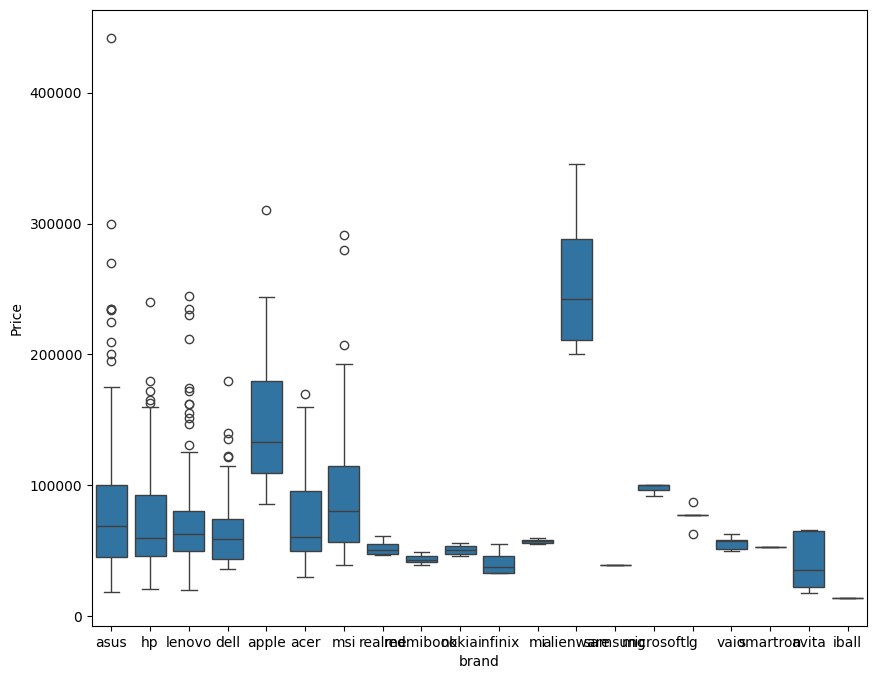

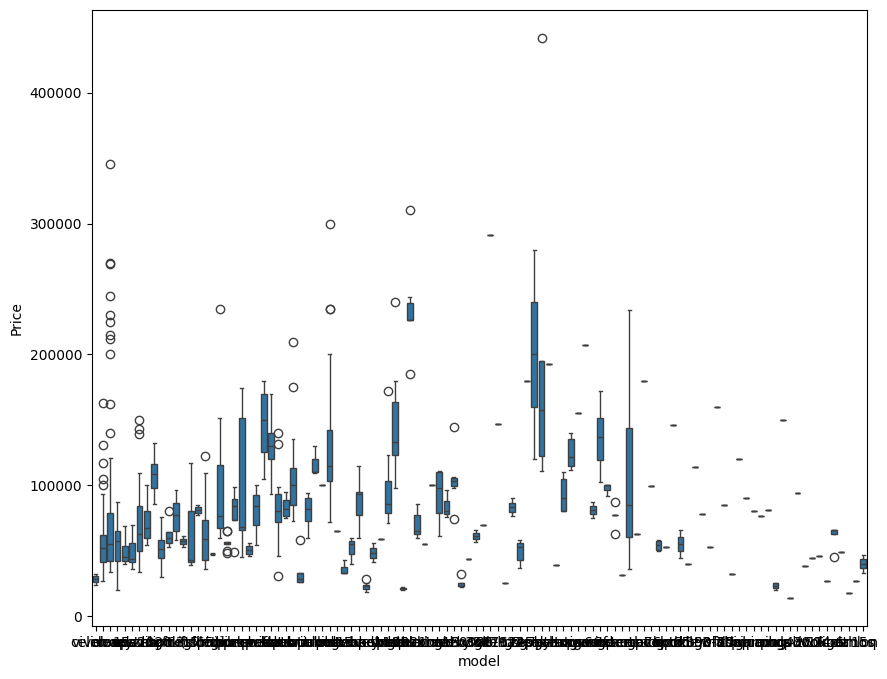

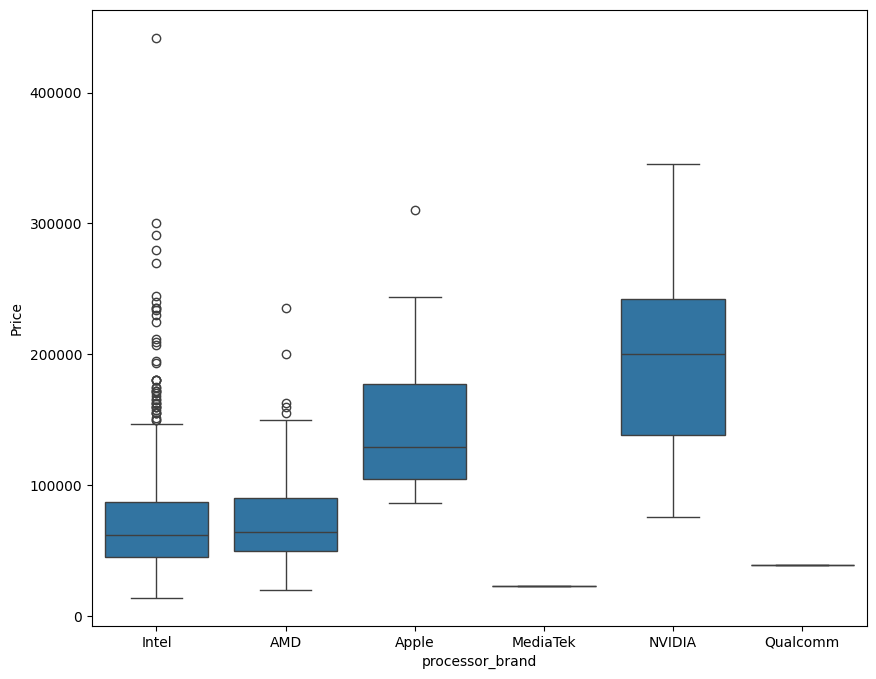

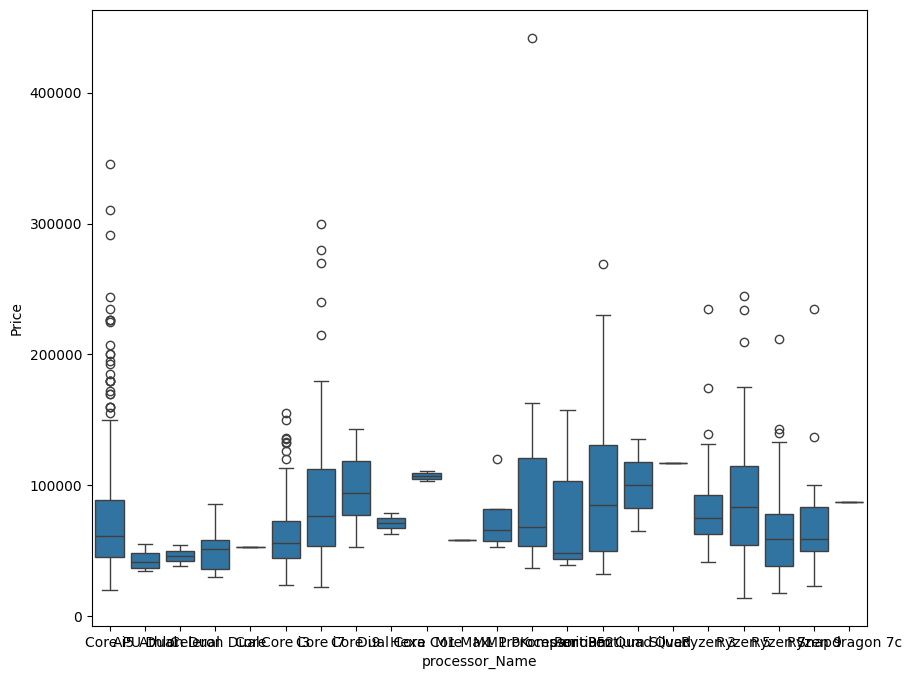

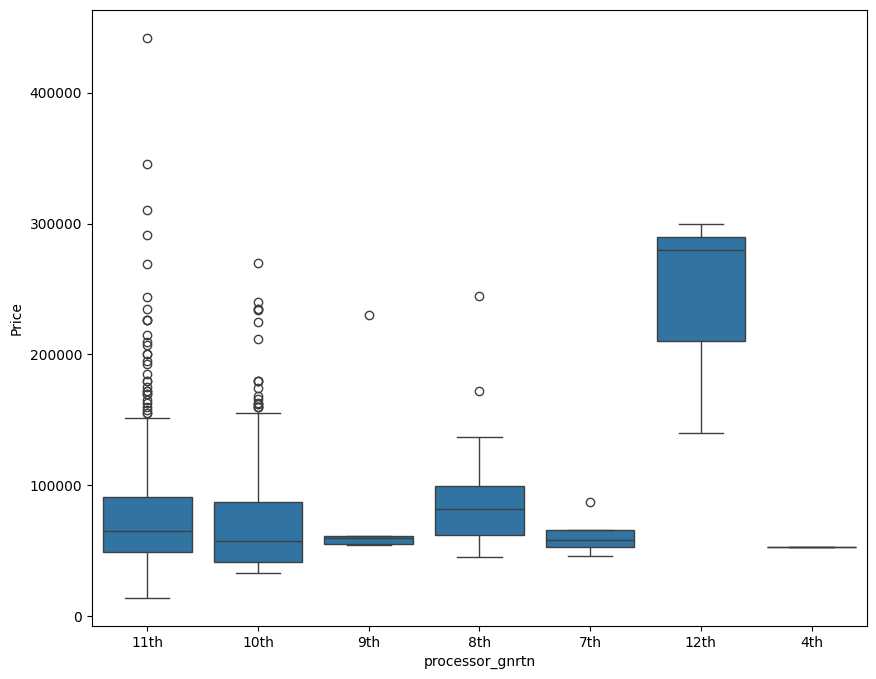

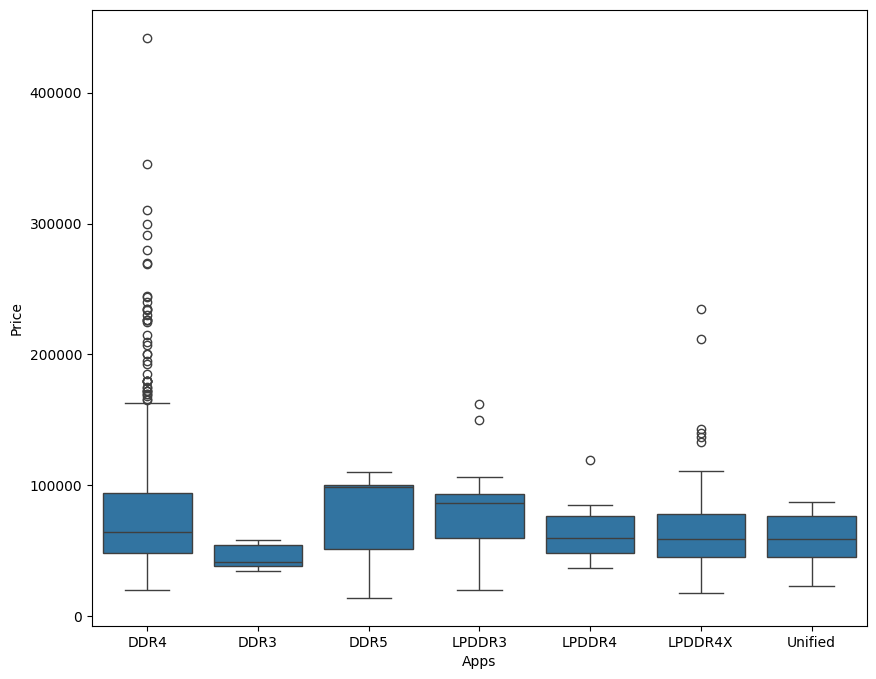

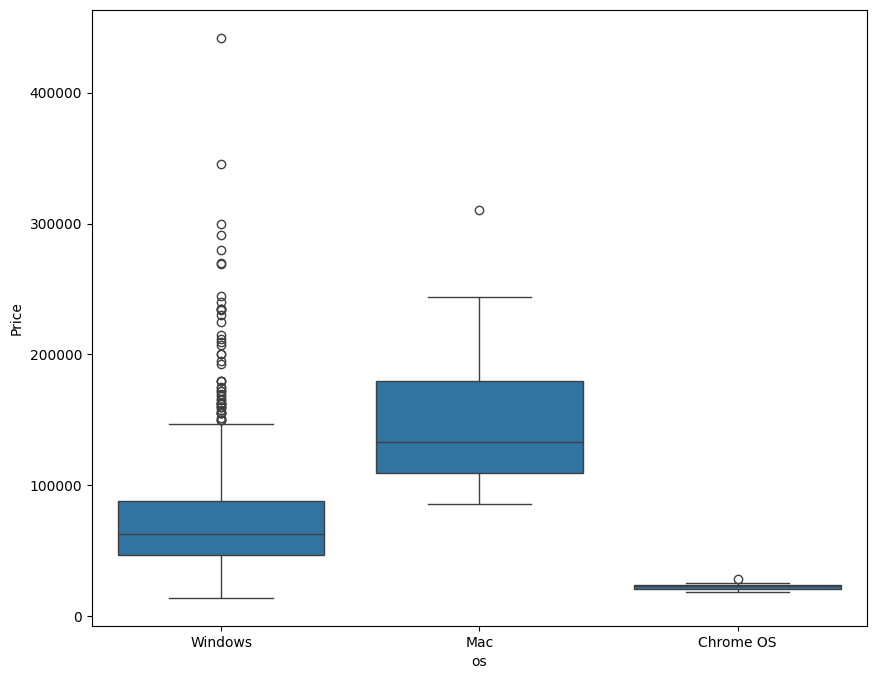

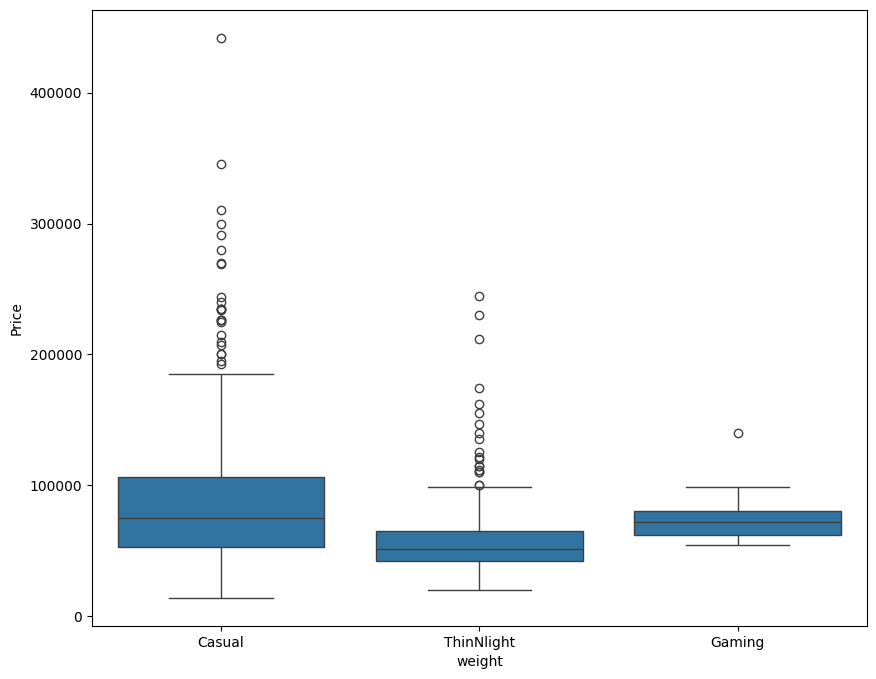

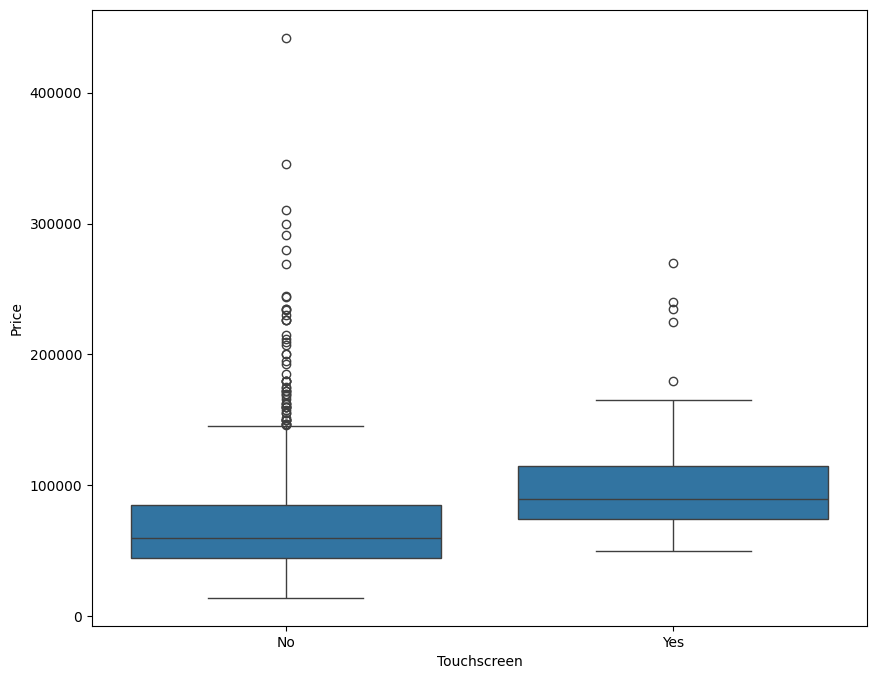

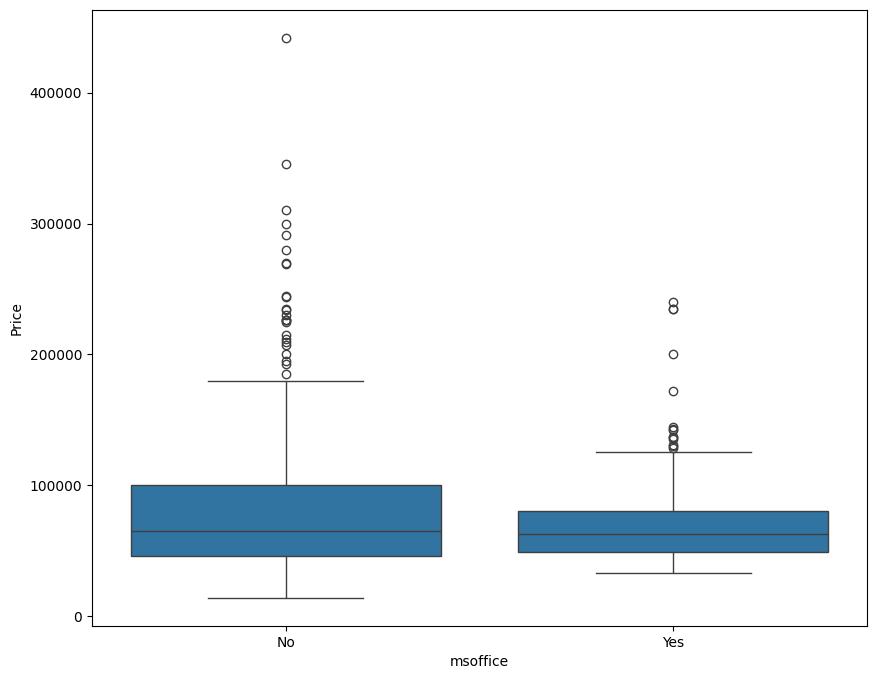

In [840]:
df_object_columns = df.select_dtypes(include=['object']).columns

for x in df_object_columns:
  plt.figure(figsize=(10, 8))
  sns.boxplot(x=x, y = 'Price', data = df_object)

In [841]:
df_encoded = pd.get_dummies(df_object,columns=['brand', 'model', 'processor_brand', 'processor_Name', 'processor_gnrtn', 'Apps', 'os', 'weight'],prefix=[
'brand', 'model', 'processor_brand', 'processor_Name', 'processor_gnrtn', 'Apps', 'os', 'weight'])

In [842]:
df_encoded['Touchscreen'] = df['Touchscreen'].map({'Yes': 1, 'No': 0}).astype('int8')
df_encoded['msoffice'] = df['msoffice'].map({'Yes': 1, 'No': 0}).astype('int8')

In [843]:
df_encoded = df_encoded.drop('Price',axis=1)

In [844]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 842 entries, 0 to 844
Columns: 176 entries, Touchscreen to weight_ThinNlight
dtypes: bool(174), int8(2)
memory usage: 151.3 KB


In [845]:
df_numeric = df.select_dtypes(exclude='object')

<Axes: >

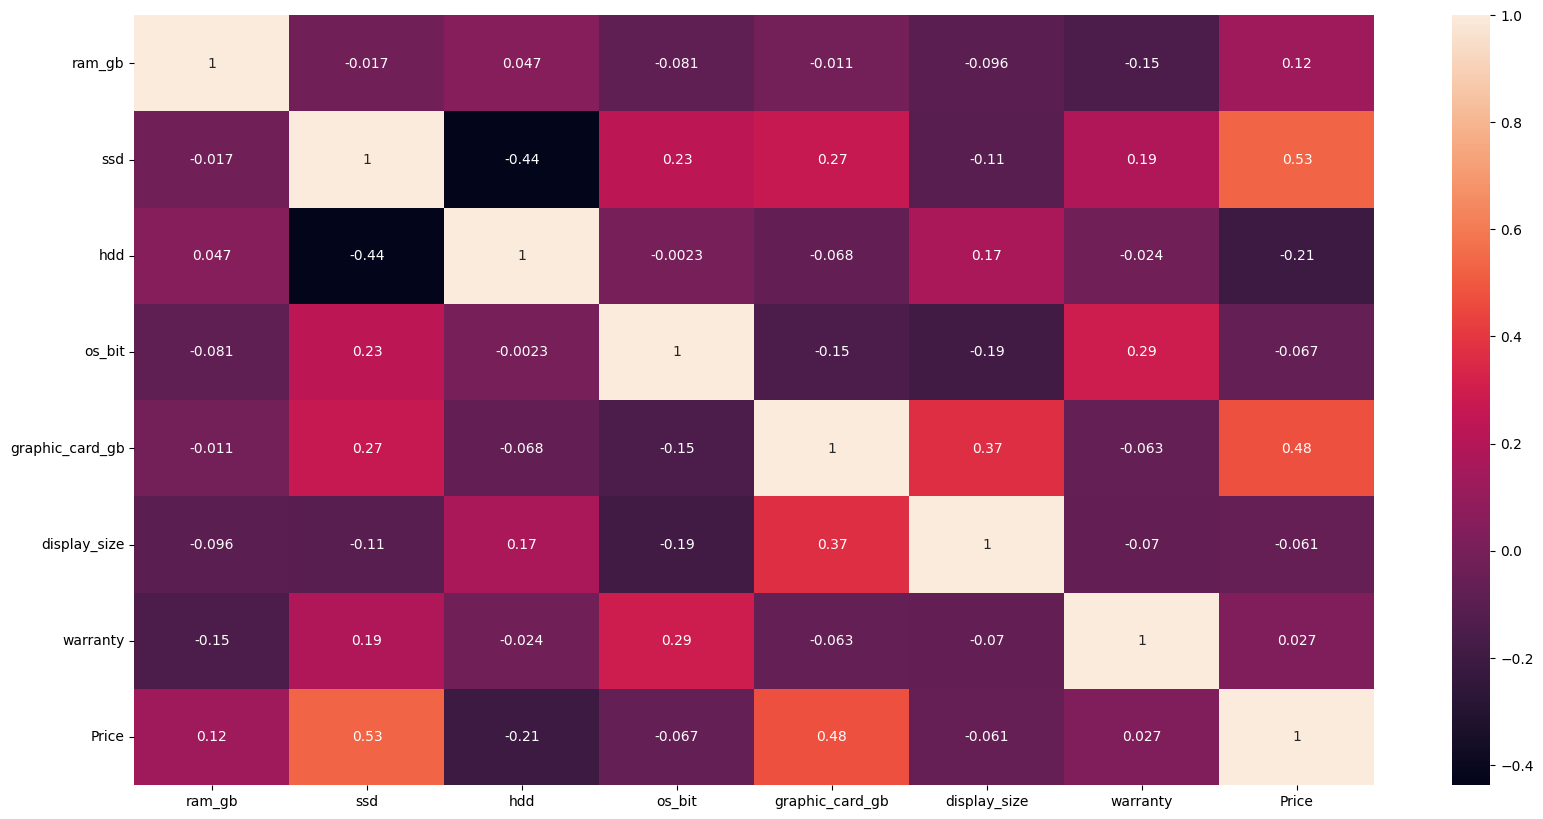

In [846]:
plt.figure(figsize=(20,10))
sns.heatmap(df_numeric.corr(),annot=True)

In [847]:
df_corr = df_numeric.corr()
df_price_corr = df_corr['Price'].abs()
highly_correlated_features = df_price_corr[df_price_corr > 0.4].index.drop('Price')
df_numeric_1 = df_numeric[highly_correlated_features]

In [848]:
df_numeric_1

,ssd,graphic_card_gb
0,0,0
1,512,0
3,512,0
4,512,0
5,0,0
...,...,...
840,512,0
841,512,4
842,0,0
843,512,2


In [849]:
df_final = pd.concat([df_encoded,df_numeric_1,df['Price']],axis=1)

In [850]:
df_final.columns

Index(['Touchscreen', 'msoffice', 'brand_acer', 'brand_alienware',
       'brand_apple', 'brand_asus', 'brand_avita', 'brand_dell', 'brand_hp',
       'brand_iball',
       ...
       'Apps_Unified', 'os_Chrome OS', 'os_Mac', 'os_Windows', 'weight_Casual',
       'weight_Gaming', 'weight_ThinNlight', 'ssd', 'graphic_card_gb',
       'Price'],
      dtype='object', length=179)

In [851]:
X = df_final.iloc[:,:-1]
y = df_final['Price']
X , y

(     Touchscreen  msoffice  brand_acer  brand_alienware  brand_apple  \
 0              0         0       False            False        False   
 1              0         0       False            False        False   
 3              0         1       False            False        False   
 4              0         0       False            False        False   
 5              0         1       False            False        False   
 ..           ...       ...         ...              ...          ...   
 840            0         0       False            False        False   
 841            0         1       False            False        False   
 842            0         0       False            False        False   
 843            0         1       False            False        False   
 844            1         1       False            False        False   
 
      brand_asus  brand_avita  brand_dell  brand_hp  brand_iball  ...  \
 0          True        False       False     Fal

In [852]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [853]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((673, 178), (169, 178), (673,), (169,))

In [854]:
scaler = MinMaxScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train),columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test),columns=X_test.columns)

In [855]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((673, 178), (169, 178), (673,), (169,))

In [856]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

In [857]:
linear_model.score(X_test, y_test), linear_model.score(X_train, y_train)

(0.5356642633031412, 0.8182912686383377)

In [858]:
y_pred_linear = linear_model.predict(X_test)

In [859]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

In [860]:
mae_linear, rmse_linear, r2_linear

(20277.691781909936, np.float64(33913.31032753366), 0.5356642633031412)

In [861]:
scores_linear = cross_val_score(linear_model, X, y, cv=5, scoring='r2')

In [867]:
scores_linear

array([0.43544234, 0.52609539, 0.67916173, 0.57139077, 0.20761301])

In [862]:
random_forest = RandomForestRegressor()
random_forest.fit(X_train, y_train)

RandomForestRegressor()

In [863]:
random_forest.score(X_test, y_test), random_forest.score(X_train, y_train)

(0.43117022897975177, 0.9566406922713927)

In [864]:
y_pred_rforrest = random_forest.predict(X_test)

In [865]:
mae_rforrest = mean_absolute_error(y_test, y_pred_rforrest)
mse_rforrest = mean_squared_error(y_test, y_pred_rforrest)
rmse_rforrest = np.sqrt(mse_rforrest)
r2_rforrest = r2_score(y_test, y_pred_rforrest)

In [866]:
mae_rforrest, rmse_rforrest, r2_rforrest

(18712.12826952108, np.float64(37535.766449783034), 0.43117022897975177)

In [868]:
scores_rforrest = cross_val_score(random_forest, X, y, cv=5, scoring='r2')

In [869]:
scores_rforrest

array([0.5568456 , 0.58753032, 0.65441182, 0.59777701, 0.40417166])